In [1]:
import os
import sys
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

from pathlib import Path

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.12.10 (v3.12.10:0cc81280367, Apr  8 2025, 08:47:00) [Clang 13.0.0 (clang-1300.0.29.30)]
Pandas: 2.2.3
NumPy: 1.26.4
Scikit-learn: 1.9.1


In [2]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"
ML_OUTPUT_PATH = PROCESSED_PATH / "ml"

ML_OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

MODEL_PATH = PROJECT_ROOT / "models"
MODEL_PATH.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("ML output:", ML_OUTPUT_PATH)
print("Models:", MODEL_PATH)

Project: /Users/rizwansalim/Desktop/SkillBridgeByZequa
ML output: /Users/rizwansalim/Desktop/SkillBridgeByZequa/data/processed/ml
Models: /Users/rizwansalim/Desktop/SkillBridgeByZequa/models


In [3]:
occupations = pd.read_csv(
    PROCESSED_PATH / "unified_occupations.csv"
)

skills = pd.read_csv(
    PROCESSED_PATH / "unified_skills.csv"
)

esco_relationships = pd.read_csv(
    PROCESSED_PATH / "esco_occupation_skill_relationships.csv"
)

onet_relationships = pd.read_csv(
    PROCESSED_PATH / "onet_occupation_skill_relationships.csv"
)

job_titles = pd.read_csv(
    PROCESSED_PATH / "normalized_onet_job_titles.csv"
)

In [4]:
datasets = {
    "Occupations": occupations,
    "Skills": skills,
    "ESCO Relationships": esco_relationships,
    "O*NET Relationships": onet_relationships,
    "Job Titles": job_titles
}

for name, df in datasets.items():

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Column names:", df.columns.tolist())
    print("Missing values:", df.isnull().sum().sum())


Occupations
Rows: 4055
Columns: 3
Column names: ['Occupation ID', 'Occupation Name', 'Source']
Missing values: 0

Skills
Rows: 13949
Columns: 3
Column names: ['Skill ID', 'Skill Name', 'Source']
Missing values: 0

ESCO Relationships
Rows: 126051
Columns: 6
Column names: ['occupationUri', 'occupationLabel', 'relationType', 'skillType', 'skillUri', 'skillLabel']
Missing values: 59

O*NET Relationships
Rows: 18200
Columns: 7
Column names: ['Occupation ID', 'Occupation Name', 'Skill ID', 'Skill Name', 'Measurement ID', 'Measurement Name', 'Skill Rating']
Missing values: 0

Job Titles
Rows: 54269
Columns: 6
Column names: ['O*NET-SOC Code', 'Title', 'Job Title', 'Short Title', 'Source(s)', 'Normalized Job Title']
Missing values: 49814


In [5]:
dataset_summary = []

for name, df in datasets.items():

    dataset_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

dataset_summary = pd.DataFrame(dataset_summary)

display(dataset_summary)

dataset_summary.to_csv(
    ML_OUTPUT_PATH / "ml_dataset_summary.csv",
    index=False
)

print("Dataset summary saved successfully!")

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,Occupations,4055,3,0,0
1,Skills,13949,3,0,0
2,ESCO Relationships,126051,6,59,0
3,O*NET Relationships,18200,7,0,0
4,Job Titles,54269,6,49814,0


Dataset summary saved successfully!


In [6]:
print("ESCO columns:")
print(esco_relationships.columns.tolist())

print("\nO*NET columns:")
print(onet_relationships.columns.tolist())

ESCO columns:
['occupationUri', 'occupationLabel', 'relationType', 'skillType', 'skillUri', 'skillLabel']

O*NET columns:
['Occupation ID', 'Occupation Name', 'Skill ID', 'Skill Name', 'Measurement ID', 'Measurement Name', 'Skill Rating']


In [7]:
esco_features = (
    esco_relationships
    .groupby("occupationUri")
    .agg(
        Total_Skills=("skillUri", "nunique"),
        Unique_Skill_Names=("skillLabel", "nunique")
    )
    .reset_index()
)

esco_features.rename(
    columns={"occupationUri": "Occupation ID"},
    inplace=True
)

display(esco_features.head())

,Occupation ID,Total_Skills,Unique_Skill_Names
0,http://data.europa.eu/esco/occupation/00030d09...,10,10
1,http://data.europa.eu/esco/occupation/000e93a3...,39,39
2,http://data.europa.eu/esco/occupation/0019b951...,43,43
3,http://data.europa.eu/esco/occupation/0022f466...,55,55
4,http://data.europa.eu/esco/occupation/002da35b...,29,29


In [8]:
onet_features = (
    onet_relationships
    .groupby("Occupation ID")
    .agg(
        Total_Skills=("Skill Name", "nunique")
    )
    .reset_index()
)

display(onet_features.head())

,Occupation ID,Total_Skills
0,11-1011.00,10
1,11-1011.03,10
2,11-1021.00,10
3,11-2011.00,10
4,11-2021.00,10


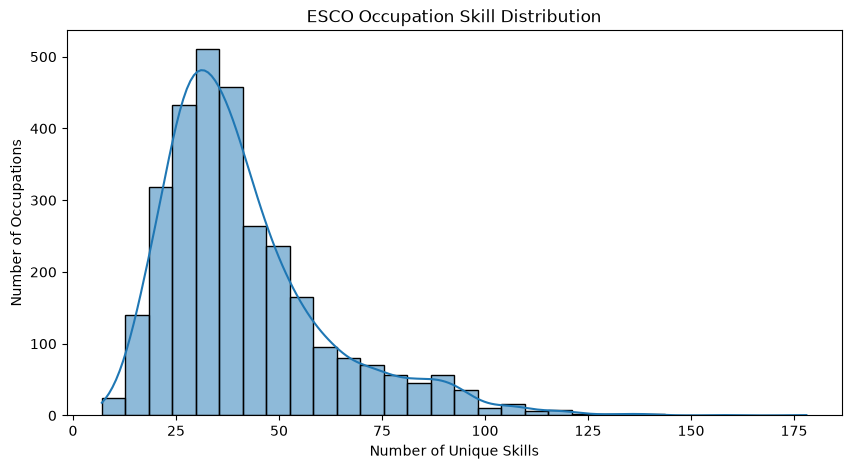

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=esco_features,
    x="Total_Skills",
    bins=30,
    kde=True
)

plt.title("ESCO Occupation Skill Distribution")
plt.xlabel("Number of Unique Skills")
plt.ylabel("Number of Occupations")
plt.show()

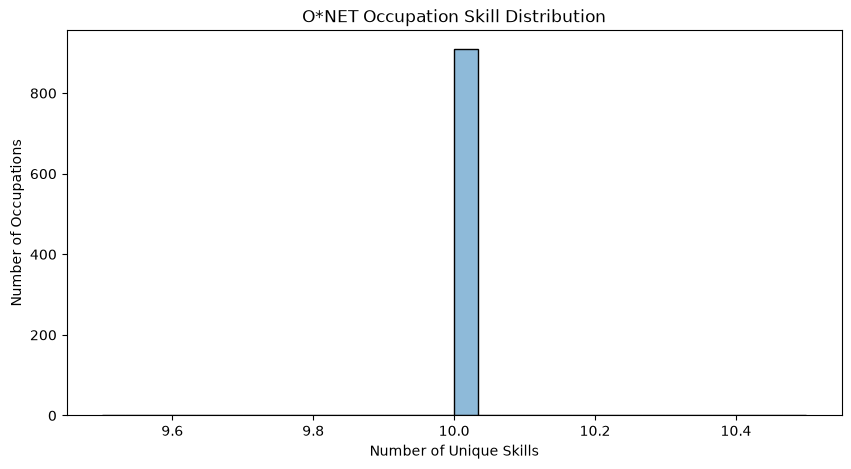

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=onet_features,
    x="Total_Skills",
    bins=30,
    kde=True
)

plt.title("O*NET Occupation Skill Distribution")
plt.xlabel("Number of Unique Skills")
plt.ylabel("Number of Occupations")
plt.show()

In [11]:
esco_features["Skill_Density"] = (
    esco_features["Total_Skills"] /
    esco_features["Total_Skills"].max()
)

onet_features["Skill_Density"] = (
    onet_features["Total_Skills"] /
    onet_features["Total_Skills"].max()
)

print("ESCO features:")
display(esco_features.describe())

print("O*NET features:")
display(onet_features.describe())

ESCO features:


,Total_Skills,Unique_Skill_Names,Skill_Density
count,3039.000000,3039.000000,3039.000000
mean,41.477789,41.477789,0.233021
std,20.216995,20.216995,0.113579
min,7.000000,7.000000,0.039326
25%,28.000000,28.000000,0.157303
50%,37.000000,37.000000,0.207865
75%,49.000000,49.000000,0.275281
max,178.000000,178.000000,1.000000


O*NET features:


,Total_Skills,Skill_Density
count,910.0,910.0
mean,10.0,1.0
std,0.0,0.0
min,10.0,1.0
25%,10.0,1.0
50%,10.0,1.0
75%,10.0,1.0
max,10.0,1.0


In [12]:
esco_features.to_csv(
    ML_OUTPUT_PATH / "esco_occupation_features.csv",
    index=False
)

onet_features.to_csv(
    ML_OUTPUT_PATH / "onet_occupation_features.csv",
    index=False
)

print("Feature engineering completed!")

Feature engineering completed!


In [13]:
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    LabelEncoder,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [14]:
ml_dataset = occupations.copy()

print("Dataset shape:", ml_dataset.shape)
print("\nColumns:")
print(ml_dataset.columns.tolist())

display(ml_dataset.head())

Dataset shape: (4055, 3)

Columns:
['Occupation ID', 'Occupation Name', 'Source']


,Occupation ID,Occupation Name,Source
0,http://data.europa.eu/esco/occupation/00030d09...,technical director,ESCO
1,http://data.europa.eu/esco/occupation/000e93a3...,metal drawing machine operator,ESCO
2,http://data.europa.eu/esco/occupation/0019b951...,precision device inspector,ESCO
3,http://data.europa.eu/esco/occupation/0022f466...,air traffic safety technician,ESCO
4,http://data.europa.eu/esco/occupation/002da35b...,hospitality revenue manager,ESCO


In [15]:
missing_report = pd.DataFrame({
    "Missing Values": ml_dataset.isnull().sum(),
    "Missing Percentage": (
        ml_dataset.isnull().mean() * 100
    ).round(2)
})

display(missing_report)

,Missing Values,Missing Percentage
Occupation ID,0,0.0
Occupation Name,0,0.0
Source,0,0.0


In [16]:
categorical_columns = ["Source"]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoded_data = encoder.fit_transform(
    ml_dataset[categorical_columns]
)

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(categorical_columns)
)

display(encoded_df.head())

,Source_ESCO,Source_O*NET
0,1.0,0.0
1,1.0,0.0
2,1.0,0.0
3,1.0,0.0
4,1.0,0.0


In [17]:
numeric_features = esco_features[
    ["Total_Skills", "Unique_Skill_Names", "Skill_Density"]
].copy()

scaler = StandardScaler()

scaled_features = scaler.fit_transform(numeric_features)

scaled_df = pd.DataFrame(
    scaled_features,
    columns=[
        "Total_Skills_Scaled",
        "Unique_Skill_Names_Scaled",
        "Skill_Density_Scaled"
    ]
)

display(scaled_df.head())

,Total_Skills_Scaled,Unique_Skill_Names_Scaled,Skill_Density_Scaled
0,-1.557253,-1.557253,-1.557253
1,-0.122580,-0.122580,-0.122580
2,0.075306,0.075306,0.075306
3,0.668964,0.668964,0.668964
4,-0.617295,-0.617295,-0.617295


In [18]:
minmax_scaler = MinMaxScaler()

minmax_features = minmax_scaler.fit_transform(
    numeric_features
)

minmax_df = pd.DataFrame(
    minmax_features,
    columns=numeric_features.columns
)

display(minmax_df.head())

,Total_Skills,Unique_Skill_Names,Skill_Density
0,0.017544,0.017544,0.017544
1,0.187135,0.187135,0.187135
2,0.210526,0.210526,0.210526
3,0.280702,0.280702,0.280702
4,0.128655,0.128655,0.128655


In [19]:
encoded_df.to_csv(
    ML_OUTPUT_PATH / "encoded_occupation_sources.csv",
    index=False
)

scaled_df.to_csv(
    ML_OUTPUT_PATH / "scaled_occupation_features.csv",
    index=False
)

minmax_df.to_csv(
    ML_OUTPUT_PATH / "minmax_occupation_features.csv",
    index=False
)

print("Preprocessing outputs saved successfully!")

Preprocessing outputs saved successfully!


In [20]:
positive_pairs = (
    esco_relationships[
        ["occupationUri", "occupationLabel", "skillUri", "skillLabel"]
    ]
    .dropna()
    .drop_duplicates()
    .copy()
)

positive_pairs["Has_Skill"] = 1

print("Positive examples:", len(positive_pairs))
positive_pairs.head()

Positive examples: 126051


,occupationUri,occupationLabel,skillUri,skillLabel,Has_Skill
0,http://data.europa.eu/esco/occupation/00030d09...,technical director,http://data.europa.eu/esco/skill/fed5b267-73fa...,theatre techniques,1
1,http://data.europa.eu/esco/occupation/00030d09...,technical director,http://data.europa.eu/esco/skill/05bc7677-5a64...,organise rehearsals,1
2,http://data.europa.eu/esco/occupation/00030d09...,technical director,http://data.europa.eu/esco/skill/271a36a0-bc7a...,write risk assessment on performing arts produ...,1
3,http://data.europa.eu/esco/occupation/00030d09...,technical director,http://data.europa.eu/esco/skill/47ed1d37-971b...,coordinate with creative departments,1
4,http://data.europa.eu/esco/occupation/00030d09...,technical director,http://data.europa.eu/esco/skill/591dd514-735b...,adapt to artists' creative demands,1


In [21]:
rng = np.random.default_rng(42)

occupation_lookup = positive_pairs[
    ["occupationUri", "occupationLabel"]
].drop_duplicates()

skill_lookup = positive_pairs[
    ["skillUri", "skillLabel"]
].drop_duplicates()

positive_keys = set(
    zip(positive_pairs["occupationUri"], positive_pairs["skillUri"])
)

sample_count = len(positive_pairs) * 5

negative_candidates = pd.DataFrame({
    "occupationUri": rng.choice(
        occupation_lookup["occupationUri"].to_numpy(),
        size=sample_count
    ),
    "skillUri": rng.choice(
        skill_lookup["skillUri"].to_numpy(),
        size=sample_count
    )
}).drop_duplicates()

candidate_keys = list(zip(
    negative_candidates["occupationUri"],
    negative_candidates["skillUri"]
))

valid_mask = np.fromiter(
    (pair not in positive_keys for pair in candidate_keys),
    dtype=bool,
    count=len(candidate_keys)
)

negative_pairs = (
    negative_candidates[valid_mask]
    .merge(occupation_lookup, on="occupationUri")
    .merge(skill_lookup, on="skillUri")
    .head(len(positive_pairs))
    .copy()
)

if len(negative_pairs) < len(positive_pairs):
    raise ValueError("Not enough negative examples. Generate more candidates.")

negative_pairs["Has_Skill"] = 0

print("Negative examples:", len(negative_pairs))

Negative examples: 126051


In [22]:
ml_training_dataset = pd.concat(
    [positive_pairs, negative_pairs],
    ignore_index=True
)

ml_training_dataset = ml_training_dataset.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Final dataset shape:", ml_training_dataset.shape)
print("\nTarget distribution:")
print(ml_training_dataset["Has_Skill"].value_counts())

ml_training_dataset.head()

Final dataset shape: (252102, 5)

Target distribution:
Has_Skill
1    126051
0    126051
Name: count, dtype: int64


,occupationUri,occupationLabel,skillUri,skillLabel,Has_Skill
0,http://data.europa.eu/esco/occupation/6e5ceba0...,numerical tool and process control programmer,http://data.europa.eu/esco/skill/3b3b7373-220a...,quality and cycle time optimisation,1
1,http://data.europa.eu/esco/occupation/2e8820ba...,biomedical scientist,http://data.europa.eu/esco/skill/355c4510-8b6c...,analyse cell cultures,1
2,http://data.europa.eu/esco/occupation/6ebe4e2e...,paper mill supervisor,http://data.europa.eu/esco/skill/9b55d4b6-d015...,functionalities of machinery,1
3,http://data.europa.eu/esco/occupation/511c8e9f...,railway infrastructure inspector,http://data.europa.eu/esco/skill/37838e04-ac5f...,advise on safety improvements,1
4,http://data.europa.eu/esco/occupation/555235ce...,military engineer,http://data.europa.eu/esco/skill/0a9acb6b-1139...,Agile project management,1


In [23]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_indices, test_indices = next(
    splitter.split(
        ml_training_dataset,
        ml_training_dataset["Has_Skill"],
        groups=ml_training_dataset["occupationUri"]
    )
)

train_data = ml_training_dataset.iloc[train_indices].copy()
test_data = ml_training_dataset.iloc[test_indices].copy()

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

print(
    "Overlapping occupations:",
    len(
        set(train_data["occupationUri"])
        & set(test_data["occupationUri"])
    )
)

Training shape: (201738, 5)
Testing shape: (50364, 5)
Overlapping occupations: 0


In [24]:
ml_training_dataset.to_csv(
    ML_OUTPUT_PATH / "ml_training_dataset.csv",
    index=False
)

train_data.to_csv(
    ML_OUTPUT_PATH / "ml_train.csv",
    index=False
)

test_data.to_csv(
    ML_OUTPUT_PATH / "ml_test.csv",
    index=False
)

print("ML training datasets saved successfully!")

ML training datasets saved successfully!


In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from scipy.sparse import hstack

In [26]:
X_train_text = (
    train_data["occupationLabel"].astype(str)
    + " [SEP] "
    + train_data["skillLabel"].astype(str)
)

X_test_text = (
    test_data["occupationLabel"].astype(str)
    + " [SEP] "
    + test_data["skillLabel"].astype(str)
)

y_train = train_data["Has_Skill"]
y_test = test_data["Has_Skill"]

print("Training examples:", len(X_train_text))
print("Testing examples:", len(X_test_text))

Training examples: 201738
Testing examples: 50364


In [27]:
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10000,
    min_df=2
)

X_train = tfidf_vectorizer.fit_transform(X_train_text)
X_test = tfidf_vectorizer.transform(X_test_text)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Training feature shape: (201738, 10000)
Testing feature shape: (50364, 10000)


In [28]:
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10000,
    min_df=2
)

X_train = tfidf_vectorizer.fit_transform(X_train_text)
X_test = tfidf_vectorizer.transform(X_test_text)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Training feature shape: (201738, 10000)
Testing feature shape: (50364, 10000)


In [29]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [30]:
y_pred = logistic_model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
[0 1 0 0 0 0 0 0 1 1 0 0 1 0 1 0 0 0 0 0]


In [31]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.7104
Precision: 0.7592
Recall: 0.6207
F1 Score: 0.683

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.80      0.73     25052
           1       0.76      0.62      0.68     25312

    accuracy                           0.71     50364
   macro avg       0.72      0.71      0.71     50364
weighted avg       0.72      0.71      0.71     50364


Confusion Matrix:
[[20068  4984]
 [ 9600 15712]]


In [32]:
import joblib

joblib.dump(
    logistic_model,
    MODEL_PATH / "logistic_regression_model.pkl"
)

joblib.dump(
    tfidf_vectorizer,
    MODEL_PATH / "logistic_tfidf_vectorizer.pkl"
)

print("Logistic Regression model saved successfully!")

Logistic Regression model saved successfully!


In [33]:
from sklearn.tree import DecisionTreeClassifier

In [34]:
decision_tree_model = DecisionTreeClassifier(
    max_depth=30,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42
)

In [35]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [36]:
dt_predictions = decision_tree_model.predict(X_test)

print("First 20 predictions:")
print(dt_predictions[:20])

First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0]


In [37]:
dt_accuracy = accuracy_score(y_test, dt_predictions)
dt_precision = precision_score(y_test, dt_predictions, zero_division=0)
dt_recall = recall_score(y_test, dt_predictions, zero_division=0)
dt_f1 = f1_score(y_test, dt_predictions, zero_division=0)

print("DECISION TREE RESULTS")
print("---------------------")
print("Accuracy:", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall:", round(dt_recall, 4))
print("F1 Score:", round(dt_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, dt_predictions, zero_division=0))

DECISION TREE RESULTS
---------------------
Accuracy: 0.5989
Precision: 0.7342
Recall: 0.3166
F1 Score: 0.4424

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.88      0.69     25052
           1       0.73      0.32      0.44     25312

    accuracy                           0.60     50364
   macro avg       0.65      0.60      0.56     50364
weighted avg       0.65      0.60      0.56     50364



In [38]:
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    },
    {
        "Model": "Decision Tree",
        "Accuracy": dt_accuracy,
        "Precision": dt_precision,
        "Recall": dt_recall,
        "F1 Score": dt_f1
    }
])

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.710428,0.759181,0.620733,0.683012
1,Decision Tree,0.598940,0.734219,0.316609,0.442432


In [39]:
joblib.dump(
    decision_tree_model,
    MODEL_PATH / "decision_tree_model.pkl"
)

model_comparison.to_csv(
    ML_OUTPUT_PATH / "model_comparison.csv",
    index=False
)

print("Decision Tree model saved successfully!")

Decision Tree model saved successfully!


In [40]:
from sklearn.ensemble import RandomForestClassifier

In [41]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=30,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [42]:
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [43]:
rf_predictions = random_forest_model.predict(X_test)

print("First 20 predictions:")
print(rf_predictions[:20])

First 20 predictions:
[0 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0]


In [44]:
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions, zero_division=0)
rf_recall = recall_score(y_test, rf_predictions, zero_division=0)
rf_f1 = f1_score(y_test, rf_predictions, zero_division=0)

print("RANDOM FOREST RESULTS")
print("---------------------")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions, zero_division=0))

RANDOM FOREST RESULTS
---------------------
Accuracy: 0.6411
Precision: 0.7226
Recall: 0.464
F1 Score: 0.5651

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.82      0.69     25052
           1       0.72      0.46      0.57     25312

    accuracy                           0.64     50364
   macro avg       0.66      0.64      0.63     50364
weighted avg       0.66      0.64      0.63     50364



In [45]:
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    },
    {
        "Model": "Decision Tree",
        "Accuracy": dt_accuracy,
        "Precision": dt_precision,
        "Recall": dt_recall,
        "F1 Score": dt_f1
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1 Score": rf_f1
    }
])

model_comparison = model_comparison.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.710428,0.759181,0.620733,0.683012
1,Random Forest,0.641093,0.722591,0.464009,0.565125
2,Decision Tree,0.598940,0.734219,0.316609,0.442432


In [46]:
joblib.dump(
    random_forest_model,
    MODEL_PATH / "random_forest_model.pkl"
)

model_comparison.to_csv(
    ML_OUTPUT_PATH / "model_comparison.csv",
    index=False
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [47]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [48]:
KNN_SAMPLE_SIZE = min(10000, X_train.shape[0])

rng = np.random.default_rng(42)

sample_indices = rng.choice(
    X_train.shape[0],
    size=KNN_SAMPLE_SIZE,
    replace=False
)

X_knn_train = X_train[sample_indices]
y_knn_train = y_train.iloc[sample_indices]

print("KNN training samples:", X_knn_train.shape[0])
print("Test samples:", X_test.shape[0])

KNN training samples: 10000
Test samples: 50364


In [49]:
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

In [50]:
knn_model.fit(X_knn_train, y_knn_train)

print("KNN training completed!")

KNN training completed!


In [51]:
knn_predictions = knn_model.predict(X_test)

print("First 20 predictions:")
print(knn_predictions[:20])

First 20 predictions:
[1 0 1 1 1 1 1 1 1 0 0 1 1 0 1 1 0 1 1 0]


In [52]:
knn_accuracy = accuracy_score(y_test, knn_predictions)
knn_precision = precision_score(y_test, knn_predictions, zero_division=0)
knn_recall = recall_score(y_test, knn_predictions, zero_division=0)
knn_f1 = f1_score(y_test, knn_predictions, zero_division=0)

print("KNN RESULTS")
print("-----------")
print("Accuracy:", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall:", round(knn_recall, 4))
print("F1 Score:", round(knn_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, knn_predictions, zero_division=0))

KNN RESULTS
-----------
Accuracy: 0.6388
Precision: 0.6317
Recall: 0.6748
F1 Score: 0.6525

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.60      0.62     25052
           1       0.63      0.67      0.65     25312

    accuracy                           0.64     50364
   macro avg       0.64      0.64      0.64     50364
weighted avg       0.64      0.64      0.64     50364



In [53]:
model_comparison = pd.DataFrame([
    {"Model": "Logistic Regression", "Accuracy": accuracy,
     "Precision": precision, "Recall": recall, "F1 Score": f1},

    {"Model": "Decision Tree", "Accuracy": dt_accuracy,
     "Precision": dt_precision, "Recall": dt_recall, "F1 Score": dt_f1},

    {"Model": "Random Forest", "Accuracy": rf_accuracy,
     "Precision": rf_precision, "Recall": rf_recall, "F1 Score": rf_f1},

    {"Model": "KNN", "Accuracy": knn_accuracy,
     "Precision": knn_precision, "Recall": knn_recall, "F1 Score": knn_f1}
]).sort_values("F1 Score", ascending=False).reset_index(drop=True)

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.710428,0.759181,0.620733,0.683012
1,KNN,0.638849,0.631727,0.674779,0.652544
2,Random Forest,0.641093,0.722591,0.464009,0.565125
3,Decision Tree,0.598940,0.734219,0.316609,0.442432


In [54]:
joblib.dump(
    knn_model,
    MODEL_PATH / "knn_model.pkl"
)

model_comparison.to_csv(
    ML_OUTPUT_PATH / "model_comparison.csv",
    index=False
)

print("KNN model saved successfully!")

KNN model saved successfully!


In [55]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [56]:
import xgboost as xgb

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [57]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

In [58]:
xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [59]:
xgb_predictions = xgb_model.predict(X_test)

print("First 20 predictions:")
print(xgb_predictions[:20])

First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0]


In [60]:
xgb_accuracy = accuracy_score(y_test, xgb_predictions)
xgb_precision = precision_score(y_test, xgb_predictions, zero_division=0)
xgb_recall = recall_score(y_test, xgb_predictions, zero_division=0)
xgb_f1 = f1_score(y_test, xgb_predictions, zero_division=0)

print("XGBOOST RESULTS")
print("----------------")
print("Accuracy:", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall:", round(xgb_recall, 4))
print("F1 Score:", round(xgb_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, xgb_predictions, zero_division=0))

XGBOOST RESULTS
----------------
Accuracy: 0.6386
Precision: 0.7506
Recall: 0.4207
F1 Score: 0.5392

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.86      0.70     25052
           1       0.75      0.42      0.54     25312

    accuracy                           0.64     50364
   macro avg       0.67      0.64      0.62     50364
weighted avg       0.67      0.64      0.62     50364



In [61]:
model_comparison = pd.DataFrame([
    {"Model": "Logistic Regression", "Accuracy": accuracy,
     "Precision": precision, "Recall": recall, "F1 Score": f1},

    {"Model": "Decision Tree", "Accuracy": dt_accuracy,
     "Precision": dt_precision, "Recall": dt_recall, "F1 Score": dt_f1},

    {"Model": "Random Forest", "Accuracy": rf_accuracy,
     "Precision": rf_precision, "Recall": rf_recall, "F1 Score": rf_f1},

    {"Model": "KNN", "Accuracy": knn_accuracy,
     "Precision": knn_precision, "Recall": knn_recall, "F1 Score": knn_f1},

    {"Model": "XGBoost", "Accuracy": xgb_accuracy,
     "Precision": xgb_precision, "Recall": xgb_recall, "F1 Score": xgb_f1}
]).sort_values("F1 Score", ascending=False).reset_index(drop=True)

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.710428,0.759181,0.620733,0.683012
1,KNN,0.638849,0.631727,0.674779,0.652544
2,Random Forest,0.641093,0.722591,0.464009,0.565125
3,XGBoost,0.638611,0.750617,0.420710,0.539204
4,Decision Tree,0.598940,0.734219,0.316609,0.442432


In [62]:
joblib.dump(
    xgb_model,
    MODEL_PATH / "xgboost_model.pkl"
)

model_comparison.to_csv(
    ML_OUTPUT_PATH / "model_comparison.csv",
    index=False
)

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


In [63]:
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

In [64]:
occupation_skill_matrix = (
    esco_relationships
    .drop_duplicates(["occupationUri", "skillUri"])
    .pivot_table(
        index="occupationUri",
        columns="skillUri",
        values="skillLabel",
        aggfunc="count",
        fill_value=0
    )
)

print("Occupation-skill matrix:", occupation_skill_matrix.shape)

Occupation-skill matrix: (3039, 13475)


In [65]:
X_cluster = normalize(
    occupation_skill_matrix.values,
    norm="l2"
)

print("Normalized matrix shape:", X_cluster.shape)

Normalized matrix shape: (3039, 13475)


In [66]:
kmeans_model = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_model.fit_predict(X_cluster)

print("K-Means clustering completed!")
print("Number of clusters:", len(set(cluster_labels)))

K-Means clustering completed!
Number of clusters: 5


In [67]:
silhouette = silhouette_score(
    X_cluster,
    cluster_labels,
    sample_size=min(5000, len(cluster_labels)),
    random_state=42
)

print("Silhouette Score:", round(silhouette, 4))

Silhouette Score: 0.0303


In [68]:
cluster_results = pd.DataFrame({
    "Occupation ID": occupation_skill_matrix.index,
    "Cluster": cluster_labels
})

occupation_names = (
    esco_relationships[
        ["occupationUri", "occupationLabel"]
    ]
    .drop_duplicates("occupationUri")
    .rename(columns={
        "occupationUri": "Occupation ID",
        "occupationLabel": "Occupation Name"
    })
)

cluster_results = cluster_results.merge(
    occupation_names,
    on="Occupation ID",
    how="left"
)

cluster_results.head(10)

,Occupation ID,Cluster,Occupation Name
0,http://data.europa.eu/esco/occupation/00030d09...,3,technical director
1,http://data.europa.eu/esco/occupation/000e93a3...,0,metal drawing machine operator
2,http://data.europa.eu/esco/occupation/0019b951...,0,precision device inspector
3,http://data.europa.eu/esco/occupation/0022f466...,3,air traffic safety technician
4,http://data.europa.eu/esco/occupation/002da35b...,3,hospitality revenue manager
5,http://data.europa.eu/esco/occupation/0044c991...,3,medical laboratory assistant
6,http://data.europa.eu/esco/occupation/00634fc4...,3,asphalt laboratory technician
7,http://data.europa.eu/esco/occupation/00674f21...,2,primary school teaching assistant
8,http://data.europa.eu/esco/occupation/006cc1f9...,4,physiotherapist
9,http://data.europa.eu/esco/occupation/00747307...,2,performing arts theatre instructor


Cluster
0     540
1     142
2     193
3    1944
4     220
Name: count, dtype: int64


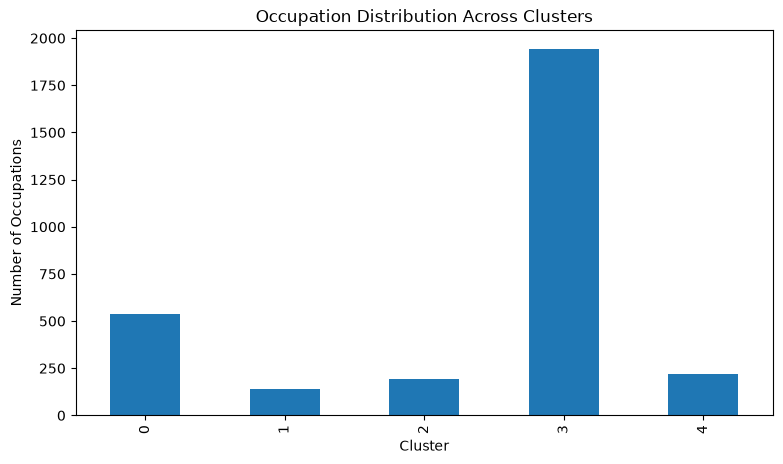

In [69]:
cluster_distribution = (
    cluster_results["Cluster"]
    .value_counts()
    .sort_index()
)

print(cluster_distribution)

cluster_distribution.plot(
    kind="bar",
    figsize=(9, 5),
    title="Occupation Distribution Across Clusters",
    xlabel="Cluster",
    ylabel="Number of Occupations"
)

plt.show()

In [70]:
cluster_results.to_csv(
    ML_OUTPUT_PATH / "occupation_clusters.csv",
    index=False
)

joblib.dump(
    kmeans_model,
    MODEL_PATH / "kmeans_occupation_model.pkl"
)

print("K-Means results and model saved successfully!")

K-Means results and model saved successfully!


In [71]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)
from sklearn.linear_model import LogisticRegression

In [72]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=1
)

print("Cross-validation scores:", cv_scores)
print("Mean F1 score:", round(cv_scores.mean(), 4))
print("Standard deviation:", round(cv_scores.std(), 4))

Cross-validation scores: [0.71006468 0.716475   0.71007358 0.70677549 0.71179243]
Mean F1 score: 0.711
Standard deviation: 0.0032


In [73]:
param_grid = {
    "C": [0.1, 1, 10],
    "solver": ["liblinear", "lbfgs"],
    "class_weight": ["balanced", None]
}

In [74]:
grid_search = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'C': 10, 'class_weight': 'balanced', 'solver': 'liblinear'}
Best cross-validation F1: 0.73


In [75]:
best_logistic_model = grid_search.best_estimator_

tuned_predictions = best_logistic_model.predict(X_test)

print("TUNED LOGISTIC REGRESSION")
print("------------------------")
print("Accuracy:", round(accuracy_score(y_test, tuned_predictions), 4))
print("Precision:", round(precision_score(y_test, tuned_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, tuned_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, tuned_predictions, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, tuned_predictions, zero_division=0))

TUNED LOGISTIC REGRESSION
------------------------
Accuracy: 0.7061
Precision: 0.7826
Recall: 0.5749
F1 Score: 0.6629

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.84      0.74     25052
           1       0.78      0.57      0.66     25312

    accuracy                           0.71     50364
   macro avg       0.72      0.71      0.70     50364
weighted avg       0.72      0.71      0.70     50364



In [76]:
joblib.dump(
    best_logistic_model,
    MODEL_PATH / "tuned_logistic_regression.pkl"
)

print("Tuned Logistic Regression model saved!")

Tuned Logistic Regression model saved!


In [77]:
final_model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    },
    {
        "Model": "Decision Tree",
        "Accuracy": dt_accuracy,
        "Precision": dt_precision,
        "Recall": dt_recall,
        "F1 Score": dt_f1
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1 Score": rf_f1
    },
    {
        "Model": "KNN",
        "Accuracy": knn_accuracy,
        "Precision": knn_precision,
        "Recall": knn_recall,
        "F1 Score": knn_f1
    },
    {
        "Model": "XGBoost",
        "Accuracy": xgb_accuracy,
        "Precision": xgb_precision,
        "Recall": xgb_recall,
        "F1 Score": xgb_f1
    },
    {
        "Model": "Tuned Logistic Regression",
        "Accuracy": accuracy_score(y_test, tuned_predictions),
        "Precision": precision_score(y_test, tuned_predictions, zero_division=0),
        "Recall": recall_score(y_test, tuned_predictions, zero_division=0),
        "F1 Score": f1_score(y_test, tuned_predictions, zero_division=0)
    }
])

final_model_comparison = (
    final_model_comparison
    .sort_values("F1 Score", ascending=False)
    .reset_index(drop=True)
)

final_model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.710428,0.759181,0.620733,0.683012
1,Tuned Logistic Regression,0.706080,0.782576,0.574905,0.662856
2,KNN,0.638849,0.631727,0.674779,0.652544
3,Random Forest,0.641093,0.722591,0.464009,0.565125
4,XGBoost,0.638611,0.750617,0.420710,0.539204
5,Decision Tree,0.598940,0.734219,0.316609,0.442432


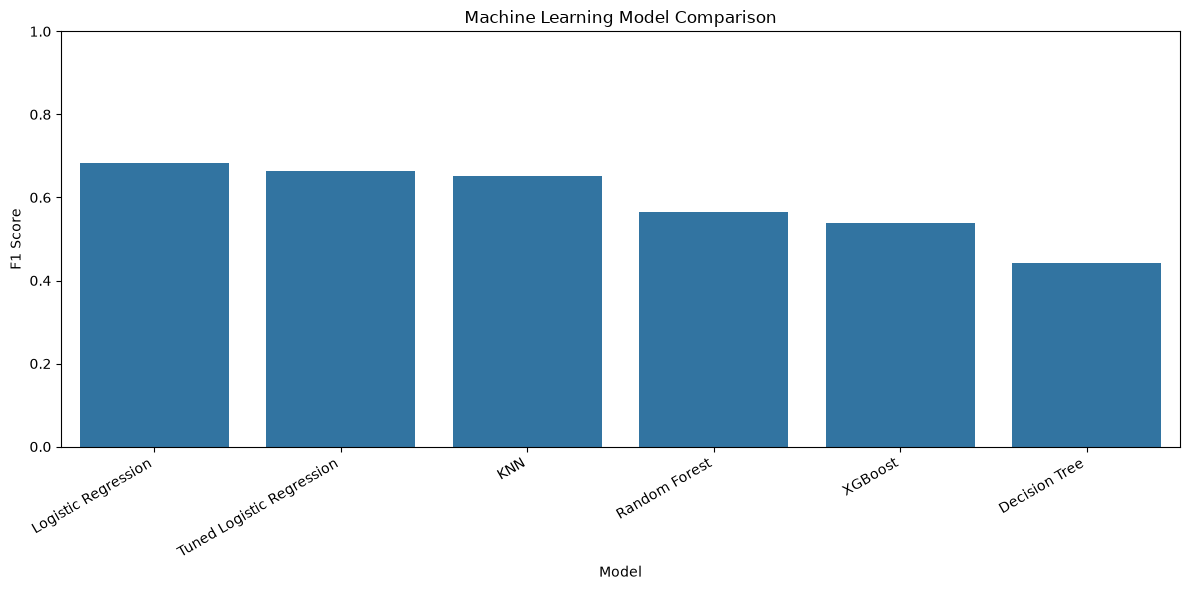

In [78]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=final_model_comparison,
    x="Model",
    y="F1 Score"
)

plt.title("Machine Learning Model Comparison")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

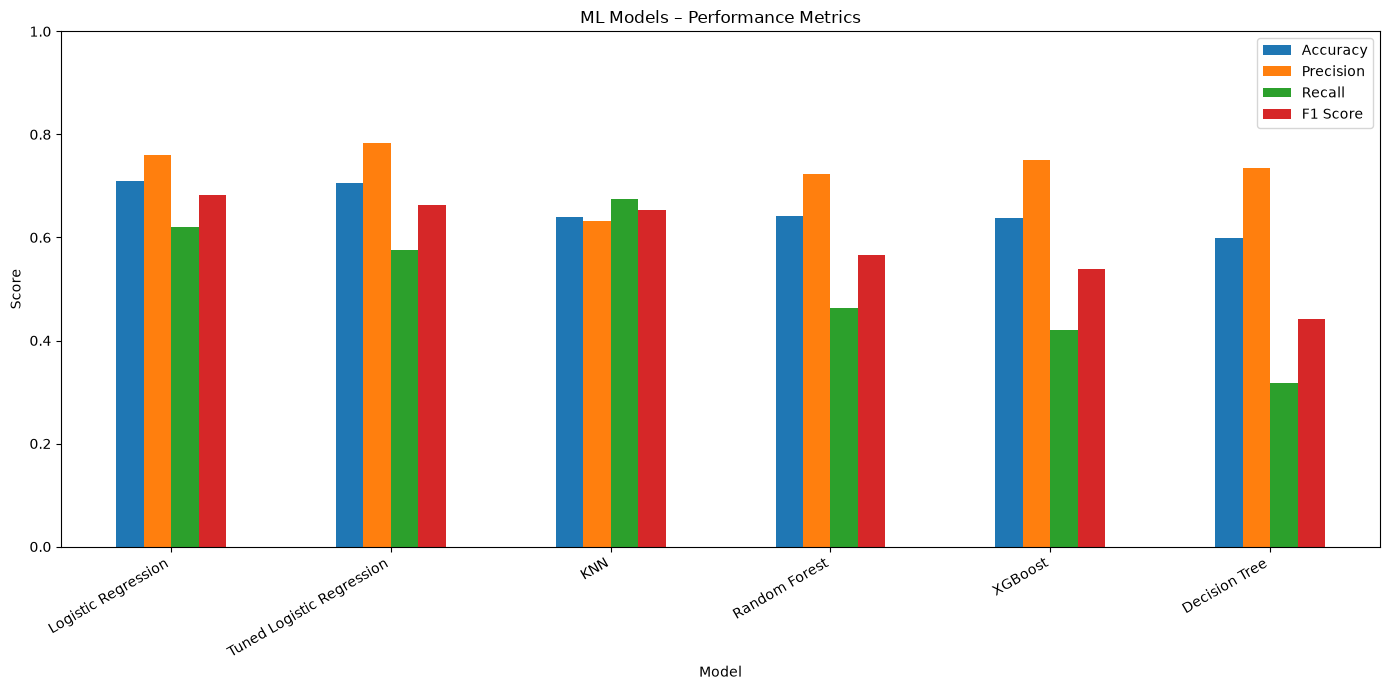

In [79]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

final_model_comparison.set_index("Model")[
    metrics_to_plot
].plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("ML Models – Performance Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [80]:
best_model_name = final_model_comparison.iloc[0]["Model"]
best_f1_score = final_model_comparison.iloc[0]["F1 Score"]

print("BEST BASELINE MODEL")
print("-------------------")
print("Model:", best_model_name)
print("F1 Score:", round(best_f1_score, 4))

BEST BASELINE MODEL
-------------------
Model: Logistic Regression
F1 Score: 0.683


In [81]:
final_model_comparison.to_csv(
    ML_OUTPUT_PATH / "final_model_comparison.csv",
    index=False
)

print("Model evaluation results saved successfully!")

Model evaluation results saved successfully!


In [82]:
feature_names = tfidf_vectorizer.get_feature_names_out()

coefficients = logistic_model.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": coefficients
})

feature_importance["Absolute_Importance"] = (
    feature_importance["Importance"].abs()
)

feature_importance = feature_importance.sort_values(
    "Absolute_Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance,Absolute_Importance
7598,sep,-25.395566,25.395566
5006,manage staff,7.514981,7.514981
4917,maintain equipment,5.509964,5.509964
7987,sep mechanics,5.039494,5.039494
9295,train employees,4.897687,4.897687
8804,supervise staff,4.485586,4.485586
4980,manage contracts,4.399054,4.399054
6343,plan transport,4.360760,4.360760
4978,manage budgets,4.336334,4.336334
9849,with customers,4.283679,4.283679


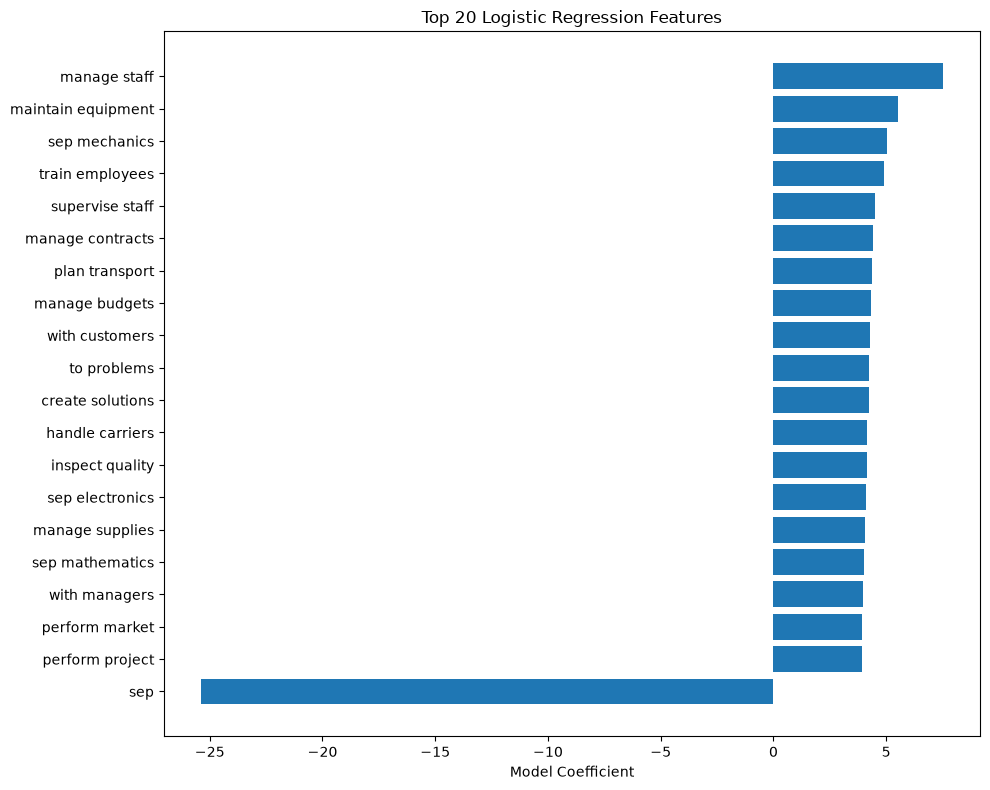

In [83]:
top_features = feature_importance.head(20).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 20 Logistic Regression Features")
plt.xlabel("Model Coefficient")
plt.tight_layout()
plt.show()

In [84]:
feature_importance.to_csv(
    ML_OUTPUT_PATH / "feature_importance.csv",
    index=False
)

print("Feature importance saved!")

Feature importance saved!


In [85]:
import joblib

final_model_package = {
    "model": logistic_model,
    "vectorizer": tfidf_vectorizer,
    "model_name": "Logistic Regression",
    "target": "Has_Skill"
}

joblib.dump(
    final_model_package,
    MODEL_PATH / "skillbridge_ml_model_package.pkl"
)

print("Final ML model package saved!")

Final ML model package saved!


In [86]:
report = f"""
SKILLBRIDGE BY ZEQUA
DAY 6 - MACHINE LEARNING REPORT
================================

PROJECT: Occupation-Skill Relationship Prediction

DATASET
-------
Total examples: {len(ml_training_dataset)}
Training examples: {len(train_data)}
Testing examples: {len(test_data)}

CLASSIFICATION MODELS
---------------------
{final_model_comparison.to_string(index=False)}

BEST BASELINE
-------------
Model: {best_model_name}
F1 Score: {best_f1_score:.4f}

CLUSTERING
----------
Number of clusters: {len(set(cluster_labels))}
Silhouette Score: {silhouette:.4f}

FEATURE ENGINEERING
-------------------
TF-IDF text representation
Occupation-skill relationship features
Occupation skill profile clustering

IMPORTANT LIMITATION
--------------------
Negative examples were randomly sampled from pairs not listed
in ESCO. They are weak negatives, not verified skill exclusions.

These results do not measure candidate employability or
real-world hiring outcomes.

================================
END OF REPORT
"""

report_path = ML_OUTPUT_PATH / "day6_ml_report.txt"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report)

print(report)


SKILLBRIDGE BY ZEQUA
DAY 6 - MACHINE LEARNING REPORT

PROJECT: Occupation-Skill Relationship Prediction

DATASET
-------
Total examples: 252102
Training examples: 201738
Testing examples: 50364

CLASSIFICATION MODELS
---------------------
                    Model  Accuracy  Precision   Recall  F1 Score
      Logistic Regression  0.710428   0.759181 0.620733  0.683012
Tuned Logistic Regression  0.706080   0.782576 0.574905  0.662856
                      KNN  0.638849   0.631727 0.674779  0.652544
            Random Forest  0.641093   0.722591 0.464009  0.565125
                  XGBoost  0.638611   0.750617 0.420710  0.539204
            Decision Tree  0.598940   0.734219 0.316609  0.442432

BEST BASELINE
-------------
Model: Logistic Regression
F1 Score: 0.6830

CLUSTERING
----------
Number of clusters: 5
Silhouette Score: 0.0303

FEATURE ENGINEERING
-------------------
TF-IDF text representation
Occupation-skill relationship features
Occupation skill profile clustering

IMPORTANT L

In [87]:
print("DAY 6 OUTPUT VALIDATION")
print("=======================")

print("\nML output files:")

for file in sorted(ML_OUTPUT_PATH.iterdir()):
    if file.is_file():
        print(file.name)

print("\nModel files:")

for file in sorted(MODEL_PATH.iterdir()):
    if file.is_file():
        print(file.name)

DAY 6 OUTPUT VALIDATION

ML output files:
day6_ml_report.txt
encoded_occupation_sources.csv
esco_occupation_features.csv
feature_importance.csv
final_model_comparison.csv
minmax_occupation_features.csv
ml_dataset_summary.csv
ml_test.csv
ml_train.csv
ml_training_dataset.csv
model_comparison.csv
occupation_clusters.csv
onet_occupation_features.csv
scaled_occupation_features.csv

Model files:
decision_tree_model.pkl
kmeans_occupation_model.pkl
knn_model.pkl
logistic_regression_model.pkl
logistic_tfidf_vectorizer.pkl
random_forest_model.pkl
skillbridge_ann.pth
skillbridge_ml_model_package.pkl
tuned_logistic_regression.pkl
xgboost_model.pkl
